# Máximo a Posteriori Composto (CMAP)
## Classificação de trajetórias de cobertura da terra — conceitos, formulação e execução passo a passo

Este notebook explica **como o classificador CMAP funciona**. Ele parte das definições, deduz a regra de decisão e executa o algoritmo, primeiro num único pixel (à mão) e depois numa cena fictícia completa. A cena é simulada aqui mesmo, então o notebook roda sem nenhum arquivo externo: só precisa de `numpy`, `pandas` e `matplotlib`.

O foco é o CMAP. As verossimilhanças de cada data, $P(\vec{o}_t \mid \omega_t)$, são tratadas como **dadas**: aqui vêm de distribuições Gaussianas conhecidas da simulação, mas em aplicações reais podem vir de qualquer modelo (Gaussiano, Gama, par de intensidades, ...).

| Seção | Conteúdo |
|---|---|
| 1 | Conceitos: transição, trajetória, trajetória inválida, comparação pós-classificação |
| 2 | Do teorema de Bayes ao MaxVer |
| 3 | A formulação do CMAP |
| 4 | Probabilidade a priori da trajetória: cadeias de Markov, abordagens discriminativa e simplificada |
| 5 | Exemplo de um pixel, resolvido à mão |
| 6 | Por que calcular em logaritmo |
| 7 | Cena fictícia: verdade, observações e verossimilhanças |
| 8 | MaxVer + comparação pós-classificação |
| 9 | CMAP na cena: abordagens simplificada e discriminativa |
| 10 | Avaliação: trajetórias inválidas, acurácia, discordância, transições e confiança |
| 11 | Datas com nuvem |
| 12 | Sensores e legendas diferentes em cada data |
| 13 | Custo computacional e uma observação sobre o algoritmo de Viterbi |
| 14 | Correspondência com o código do projeto e referências |

**Fontes principais**
- Reis, Dutra, Escada e Sant'Anna (2020b), *Avoiding invalid transitions in land cover trajectory classification with a Compound Maximum a Posteriori approach*, IEEE Access 8, 98787–98799 — proposta original do CMAP.
- Reis, Dutra e Escada (2017), *Simultaneous multi-source and multi-temporal land cover classification using a Compound Maximum Likelihood classifier*, GEOINFO — antecessor (CML).
- Queiroz (2024), *Classificação de trajetórias de cobertura da terra utilizando uma abordagem de Máximo a Posteriori Composto em imagens de multissensores*, dissertação, INPE — notação e numeração das equações (Eq. 2.x) usadas aqui.

In [1]:
import itertools
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle

rng = np.random.default_rng(2024)

# --- Legenda usada em todo o notebook (inspirada na legenda da dissertação)
CLASSES = ['F', 'VS', 'PA', 'AG']
NOMES = {'F': 'Floresta', 'VS': 'Vegetação secundária', 'PA': 'Pastagem', 'AG': 'Agricultura'}
CORES = {'F': '#1b7837', 'VS': '#8fd18a', 'PA': '#e9c46a', 'AG': '#b5651d'}
K = len(CLASSES)

# --- Estilo dos gráficos
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 11, 'font.size': 10})
CMAP_CLASSES = ListedColormap([CORES[c] for c in CLASSES])
NORM_CLASSES = BoundaryNorm(np.arange(-0.5, K + 0.5), K)
COR_INVALIDA, COR_VALIDA, COR_CMAP, COR_MAXVER = '#c0392b', '#bdbdbd', '#1f4e79', '#e07b39'


def mostrar_classes(ax, mapa, titulo, mascara=None):
    """Mapa temático com a paleta fixa das classes (pixels em `mascara` ficam em branco)."""
    img = np.ma.masked_array(mapa, mask=mascara) if mascara is not None else mapa
    ax.imshow(img, cmap=CMAP_CLASSES, norm=NORM_CLASSES, interpolation='nearest')
    ax.set_title(titulo)
    ax.set_xticks([]); ax.set_yticks([])


def legenda_classes(fig, ncol=4, y=0.0):
    fig.legend(handles=[Patch(color=CORES[c], label=f'{c} — {NOMES[c]}') for c in CLASSES],
               loc='lower center', ncol=ncol, frameon=False, bbox_to_anchor=(0.5, y))

print('Pronto. numpy', np.__version__, '| pandas', pd.__version__)

Pronto. numpy 2.5.3 | pandas 3.0.5


---
## 1. Conceitos

| Termo | Definição |
|---|---|
| **Transição** | Identificação das classes de cobertura da mesma unidade de análise (aqui, o pixel) em **dois tempos consecutivos**. Ex.: Floresta → Pastagem. |
| **Trajetória** | Sucessão de classes de cobertura de uma mesma unidade em três ou mais tempos observados, ou seja, uma sequência de transições. Ex.: Floresta → Pastagem → Vegetação secundária. |
| **Transição inválida** | Transição que não ocorre no mundo real no intervalo considerado. Ex.: Pastagem → Floresta primária em um ano. |
| **Trajetória inválida** | Trajetória com **pelo menos uma** transição inválida. |
| **Comparação pós-classificação** | Método mais usado: classificar cada imagem **independentemente** e empilhar as classificações para formar a trajetória. |

O problema da comparação pós-classificação é que a qualidade da trajetória depende da qualidade de **cada** classificação individual. Os erros se acumulam ao longo da série e produzem trajetórias inválidas, que depois precisam ser mascaradas ou corrigidas por regras manuais (Reis et al., 2020b).

> Nos estudos de caso de Reis et al. (2020b), o empilhamento de classificações MaxVer gerou trajetórias inválidas em **54,9%** dos pixels (estudo de caso 1, seis imagens TM/Landsat-5). Na dissertação, no cenário com imagens ópticas, o CMAP evitou que **57,58%** dos pixels fossem classificados em trajetórias inválidas.

O CMAP resolve isso de outra forma: em vez de classificar cada data e depois empilhar, ele **classifica a série inteira de uma vez, diretamente em trajetórias**, e usa o conhecimento sobre a dinâmica da cobertura da terra para nunca escolher uma trajetória impossível.

---
## 2. Do teorema de Bayes ao MaxVer

Seja $\vec{o}_t$ o vetor de observação de um pixel no tempo $t$ (por exemplo, os valores das bandas) e $\Omega_t = \{\omega_t^{1}, \dots, \omega_t^{K_t}\}$ o conjunto das $K_t$ classes possíveis nessa data. Pelo teorema de Bayes (Eq. 2.1):

$$P(\omega_t^i \mid \vec{o}_t) = \frac{P(\vec{o}_t \mid \omega_t^i)\, P(\omega_t^i)}{P(\vec{o}_t)}$$

| Termo | Nome |
|---|---|
| $P(\omega_t^i \mid \vec{o}_t)$ | probabilidade **a posteriori** |
| $P(\vec{o}_t \mid \omega_t^i)$ | **verossimilhança** (dada por uma função de densidade de probabilidade, FDP) |
| $P(\omega_t^i)$ | probabilidade **a priori** da classe |
| $P(\vec{o}_t) = \sum_j P(\vec{o}_t \mid \omega_t^j) P(\omega_t^j)$ | **evidência** (Eq. 2.2) — igual para todas as classes, não altera a decisão |

A regra **Máximo a Posteriori (MAP)** escolhe a classe de maior posterior (Eq. 2.3 e 2.4):

$$\vec{o}_t \in \omega_t^i \iff P(\vec{o}_t \mid \omega_t^i)\,P(\omega_t^i) > P(\vec{o}_t \mid \omega_t^j)\,P(\omega_t^j) \quad \forall\, j \neq i$$

Com classes **equiprováveis**, o prior sai da comparação e obtém-se a **Máxima Verossimilhança (MaxVer)** (Eq. 2.5):

$$\vec{o}_t \in \omega_t^i \iff P(\vec{o}_t \mid \omega_t^i) > P(\vec{o}_t \mid \omega_t^j) \quad \forall\, j \neq i$$

Para o modelo Gaussiano multivariado com $B$ bandas, vetor médio $\mathbf{m}_i$ e matriz de covariância $\Sigma_i$ (Eq. 2.6):

$$P(\vec{o}_t \mid \omega_t^i) \propto (2\pi)^{-B/2}\, |\Sigma_i|^{-1/2} \exp\!\left\{-\tfrac{1}{2}(\vec{o}_t - \mathbf{m}_i)^\intercal \Sigma_i^{-1} (\vec{o}_t - \mathbf{m}_i)\right\}$$

O MaxVer não exige a distribuição Gaussiana: qualquer FDP adequada aos dados pode ser usada (Schowengerdt, 2007, citado na dissertação). O ponto central é que **o MaxVer decide cada data isoladamente**.

---
## 3. A formulação do CMAP

A diferença entre MAP e CMAP está na **dimensionalidade** do problema. O MAP escolhe uma classe a partir de uma observação; o CMAP escolhe uma **sequência de classes** a partir de uma sequência de observações.

**Notação**

| Símbolo | Significado |
|---|---|
| $s = \{\omega_1^{k_1}, \dots, \omega_t^{k_t}, \dots, \omega_T^{k_T}\}$ | trajetória de $T$ instantes; $\omega_t^{k_t}$ é a $k_t$-ésima classe do tempo $t$ |
| $\Omega = \Omega_1 \otimes \cdots \otimes \Omega_t \otimes \cdots \otimes \Omega_T$ | conjunto de **todas** as trajetórias (produto cartesiano das legendas) |
| $\vec{O} = \{\vec{o}_1, \dots, \vec{o}_T\}$ | observações do pixel nas $T$ datas |
| $P(s)$ | probabilidade **a priori** da trajetória |

Note que cada data pode ter a **sua própria legenda** $\Omega_t$, com $K_t$ classes. É isso que permite usar sensores diferentes ao longo da série (Seção 12).

**Dedução**

1. Regra generativa: escolher a trajetória mais provável junto com as observações (Eq. 2.7):
$$\hat{s} = \arg\max_{s \in \Omega} P(s, \vec{O})$$

2. Pela definição de probabilidade condicional, $P(s, \vec{O}) = P(\vec{O} \mid s)\, P(s)$ (Eq. 2.8 e 2.9):
$$\hat{s} = \arg\max_{s \in \Omega} P(\vec{O} \mid s)\, P(s)$$

3. Supondo observações **independentes no tempo**, cada uma dependendo só da classe naquela data (Eq. 2.10):
$$P(\vec{O} \mid s) = \prod_{t=1}^{T} P(\vec{o}_t \mid \omega_t^{k_t})$$

4. Substituindo, chega-se ao **CMAP** (Eq. 2.11):
$$\boxed{\;\hat{s} = \arg\max_{s \in \Omega}\; P(s) \prod_{t=1}^{T} P(\vec{o}_t \mid \omega_t^{k_t})\;}$$

**Leitura da fórmula**
- O produto $\prod_t P(\vec{o}_t \mid \omega_t^{k_t})$ é a **verossimilhança composta** da trajetória. Sozinha, ela dá o classificador *Compound (Maximum) Likelihood* (CML) de Reis et al. (2017).
- $P(s)$ injeta o **conhecimento sobre a dinâmica**: trajetórias impossíveis recebem $P(s) = 0$ e nunca vencem.
- Se $P(s)$ for igual para todas as trajetórias, o produto é maximizado escolhendo, em cada data, a classe de maior verossimilhança. Ou seja, **CMAP com prior uniforme = MaxVer empilhado**. Toda a diferença entre os dois está em $P(s)$.

---
## 4. Probabilidade a priori da trajetória, $P(s)$

### 4.1 Cadeia de Markov

Supondo que a classe em $t$ depende apenas da classe em $t-1$ (propriedade de Markov), o prior da trajetória se fatora em (Eq. 2.12):

$$P(s) = P(\omega_1^{k_1}) \times P(\omega_2^{k_2} \mid \omega_1^{k_1}) \times \cdots \times P(\omega_T^{k_T} \mid \omega_{T-1}^{k_{T-1}})$$

Cada fator condicional vem de uma **matriz de probabilidades de transição** entre duas datas consecutivas: linhas = classe em $t-1$, colunas = classe em $t$. Junto com o **vetor de probabilidade inicial** $P(\omega_1)$, essas matrizes determinam completamente a cadeia de Markov.

### 4.2 Abordagem discriminativa

As matrizes trazem probabilidades de transição conhecidas. Como as classes são mutuamente exclusivas, **cada linha soma 1** (Eq. 2.13):

$$\sum_{k_t = 1}^{K_t} P(\omega_t^{k_t} \mid \omega_{t-1}^{k_{t-1}}) = 1$$

Reis et al. (2020b) também apresentam a forma **regressiva** (*backward*), em que a classe em $t$ depende da classe em $t+1$:

$$P(s) = P(\omega_T^{k_T}) \times P(\omega_{T-1}^{k_{T-1}} \mid \omega_T^{k_T}) \times \cdots \times P(\omega_1^{k_1} \mid \omega_2^{k_2}), \qquad \sum_{k_{t-1}} P(\omega_{t-1}^{k_{t-1}} \mid \omega_t^{k_t}) = 1$$

Nesse caso, são as **colunas** da matriz que somam 1.

### 4.3 Abordagem simplificada (matriz de validade)

Quando não se conhecem as probabilidades, basta dizer quais transições são **possíveis**. A matriz de validade tem 1 para transições possíveis e 0 para impossíveis, e:

$$P(s) = \begin{cases} 1/N_s & \text{se todas as transições de } s \text{ são válidas} \\ 0 & \text{caso contrário} \end{cases}$$

em que $N_s$ é o número de trajetórias válidas. Como $1/N_s$ é igual para todas as trajetórias válidas, essa abordagem equivale a **MaxVer restrito às trajetórias válidas**.

Abaixo estão as duas matrizes usadas no restante do notebook. A lógica é a de uma fronteira de desmatamento: a floresta primária pode ser convertida, mas nada vira floresta primária em um ano; a floresta não vira vegetação secundária sem antes ser desmatada.

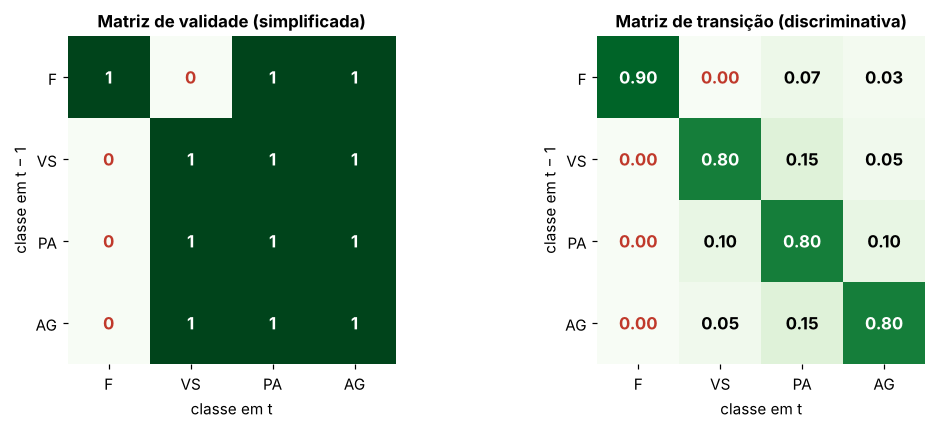

In [2]:
# Matriz de VALIDADE (abordagem simplificada): 1 = transição possível, 0 = impossível
VALIDADE = pd.DataFrame([[1, 0, 1, 1],    # F  -> F, PA, AG   (desmatamento)
                         [0, 1, 1, 1],    # VS -> VS, PA, AG  (nova supressão)
                         [0, 1, 1, 1],    # PA -> VS (abandono), PA, AG
                         [0, 1, 1, 1]],   # AG -> VS, PA, AG
                        index=CLASSES, columns=CLASSES, dtype=float)

# Matriz de PROBABILIDADES de transição (abordagem discriminativa): cada linha soma 1 (Eq. 2.13)
DISCRIMINATIVA = pd.DataFrame([[0.90, 0.00, 0.07, 0.03],
                               [0.00, 0.80, 0.15, 0.05],
                               [0.00, 0.10, 0.80, 0.10],
                               [0.00, 0.05, 0.15, 0.80]],
                              index=CLASSES, columns=CLASSES)
assert np.allclose(DISCRIMINATIVA.sum(axis=1), 1), 'Eq. 2.13 violada'
assert ((DISCRIMINATIVA > 0) == (VALIDADE > 0)).all().all(), 'as duas matrizes devem ter as mesmas transições possíveis'

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (titulo, m, fmt) in zip(axes, [('Matriz de validade (simplificada)', VALIDADE, '{:.0f}'),
                                       ('Matriz de transição (discriminativa)', DISCRIMINATIVA, '{:.2f}')]):
    ax.imshow(m.to_numpy(), cmap='Greens', vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(m.to_numpy()):
        ax.text(j, i, fmt.format(v), ha='center', va='center', fontsize=11,
                color='white' if v > 0.6 else ('#c0392b' if v == 0 else 'black'), fontweight='bold')
    ax.set_xticks(range(K), CLASSES); ax.set_yticks(range(K), CLASSES)
    ax.set_xlabel('classe em t'); ax.set_ylabel('classe em t − 1'); ax.set_title(titulo)
    ax.spines[:].set_visible(False)
plt.tight_layout(); plt.show()

---
## 5. Exemplo de um pixel, resolvido à mão

Um pixel observado em três anos, com três classes possíveis (F, PA e VS). As verossimilhanças abaixo são valores ilustrativos de $P(\vec{o}_t \mid \omega_t)$, que na prática viriam do modelo estatístico de cada data.

In [3]:
ex_classes = ['F', 'PA', 'VS']
ex_anos = ['2005', '2006', '2007']
ex_veross = pd.DataFrame([[0.60, 0.30, 0.45],     # 2005
                          [0.20, 0.50, 0.48],     # 2006
                          [0.52, 0.10, 0.50]],    # 2007
                         index=ex_anos, columns=ex_classes)
ex_validade = VALIDADE.loc[ex_classes, ex_classes]

maxver_ex = ex_veross.idxmax(axis=1)
print('MaxVer em cada data:', ' → '.join(maxver_ex))
print('Transições do MaxVer válidas?',
      [bool(ex_validade.loc[a, b]) for a, b in zip(maxver_ex[:-1], maxver_ex[1:])])
ex_veross.style.format('{:.2f}').highlight_max(axis=1, props='font-weight:bold; background-color:#fde2c8')

MaxVer em cada data: F → PA → F
Transições do MaxVer válidas? [True, False]


,F,PA,VS
2005,0.60,0.30,0.45
2006,0.20,0.50,0.48
2007,0.52,0.10,0.50


O MaxVer escolhe **F → PA → F**: o pixel teria sido desmatado em 2006 e voltado a ser floresta primária em 2007. Essa trajetória é **inválida**.

O CMAP enumera **todas** as $3^3 = 27$ trajetórias, calcula $P(s)\prod_t P(\vec{o}_t \mid \omega_t)$ para cada uma (com a abordagem simplificada, $P(s) = 1/N_s$ ou $0$) e escolhe a maior.

Trajetórias válidas: N_s = 12 de 27
Maior verossimilhança composta (= MaxVer empilhado): F → PA → F
CMAP: F → PA → VS


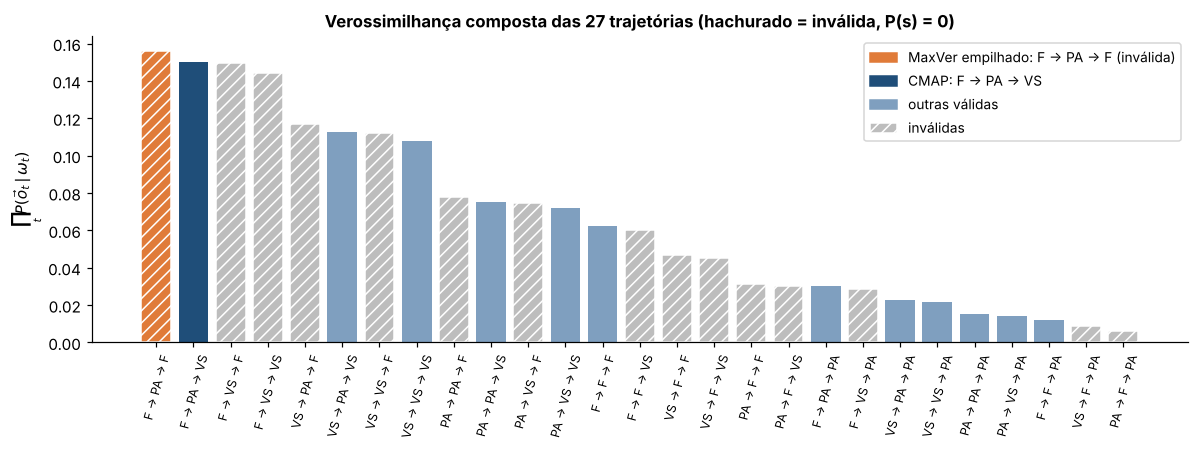

,trajetoria,valida,CML,P(s),P(s)·∏P(o|ω)
0,F → PA → F,False,0.1560,0.0000,0.00000
1,F → PA → VS,True,0.1500,0.0833,0.01250
2,F → VS → F,False,0.1498,0.0000,0.00000
3,F → VS → VS,False,0.1440,0.0000,0.00000
4,VS → PA → F,False,0.1170,0.0000,0.00000
5,VS → PA → VS,True,0.1125,0.0833,0.00937
6,VS → VS → F,False,0.1123,0.0000,0.00000
7,VS → VS → VS,True,0.1080,0.0833,0.00900


In [4]:
linhas = []
for traj in itertools.product(ex_classes, repeat=3):
    valida = all(ex_validade.loc[a, b] == 1 for a, b in zip(traj[:-1], traj[1:]))
    verossimilhanca_composta = np.prod([ex_veross.loc[ano, c] for ano, c in zip(ex_anos, traj)])   # Eq. 2.10
    linhas.append({'trajetoria': ' → '.join(traj), 'valida': valida, 'CML': verossimilhanca_composta})
tab = pd.DataFrame(linhas)
N_s = int(tab['valida'].sum())
tab['P(s)'] = np.where(tab['valida'], 1 / N_s, 0.0)                      # abordagem simplificada
tab['P(s)·∏P(o|ω)'] = tab['P(s)'] * tab['CML']                           # Eq. 2.11
tab = tab.sort_values('CML', ascending=False).reset_index(drop=True)

vencedora_cmap = tab.loc[tab['P(s)·∏P(o|ω)'].idxmax(), 'trajetoria']
vencedora_cml = tab.loc[0, 'trajetoria']
print(f'Trajetórias válidas: N_s = {N_s} de {len(tab)}')
print(f'Maior verossimilhança composta (= MaxVer empilhado): {vencedora_cml}')
print(f'CMAP: {vencedora_cmap}')

fig, ax = plt.subplots(figsize=(11, 4.2))
cores = [COR_CMAP if t == vencedora_cmap else (COR_MAXVER if t == vencedora_cml else
         ('#7f9fbf' if v else COR_VALIDA)) for t, v in zip(tab['trajetoria'], tab['valida'])]
barras = ax.bar(range(len(tab)), tab['CML'], color=cores)
for b, v in zip(barras, tab['valida']):
    if not v:
        b.set_hatch('///'); b.set_edgecolor('white')
ax.set_xticks(range(len(tab)), tab['trajetoria'], rotation=75, fontsize=8)
ax.set_ylabel(r'$\prod_t P(\vec{o}_t\,|\,\omega_t)$')
ax.set_title('Verossimilhança composta das 27 trajetórias (hachurado = inválida, P(s) = 0)')
ax.legend(handles=[Patch(color=COR_MAXVER, label=f'MaxVer empilhado: {vencedora_cml} (inválida)'),
                   Patch(color=COR_CMAP, label=f'CMAP: {vencedora_cmap}'),
                   Patch(color='#7f9fbf', label='outras válidas'),
                   Patch(facecolor=COR_VALIDA, hatch='///', edgecolor='white', label='inválidas')], fontsize=9)
plt.tight_layout(); plt.show()
tab.head(8).style.format({'CML': '{:.4f}', 'P(s)': '{:.4f}', 'P(s)·∏P(o|ω)': '{:.5f}'})

A trajetória de maior verossimilhança composta é a do MaxVer empilhado, mas ela tem $P(s) = 0$. Entre as válidas, vence **F → PA → VS**: em 2007, o CMAP troca *Floresta* por *Vegetação secundária*, a segunda classe mais verossímil naquela data e a única coerente com o desmatamento de 2006.

Isso mostra o mecanismo essencial: **o CMAP não corrige a data depois de classificar; ele simplesmente nunca considera as trajetórias impossíveis**. A informação das outras datas desempata as classes que, numa data isolada, são parecidas.

### 5.1 E com a abordagem discriminativa?

Com a matriz de probabilidades, $P(s)$ deixa de ser constante entre as trajetórias válidas e passa a **ponderá-las**. Aqui, o prior usa o vetor inicial uniforme e as linhas da matriz discriminativa restritas às três classes (renormalizadas).

In [5]:
sub = DISCRIMINATIVA.loc[ex_classes, ex_classes]
sub = sub.div(sub.sum(axis=1), axis=0)                    # renormaliza as linhas (Eq. 2.13) no subconjunto
p_inicial = 1 / len(ex_classes)

tab['P(s) discr.'] = [p_inicial * np.prod([sub.loc[a, b] for a, b in zip(t.split(' → ')[:-1], t.split(' → ')[1:])])
                      for t in tab['trajetoria']]                                    # Eq. 2.12
tab['P(s)·∏P(o|ω) discr.'] = tab['P(s) discr.'] * tab['CML']
top = tab.sort_values('P(s)·∏P(o|ω) discr.', ascending=False).head(6)
print('CMAP discriminativo:', top.iloc[0]['trajetoria'])
top[['trajetoria', 'CML', 'P(s) discr.', 'P(s)·∏P(o|ω) discr.']].style.format(
    {'CML': '{:.4f}', 'P(s) discr.': '{:.4f}', 'P(s)·∏P(o|ω) discr.': '{:.5f}'})

CMAP discriminativo: VS → VS → VS


,trajetoria,CML,P(s) discr.,P(s)·∏P(o|ω) discr.
7,VS → VS → VS,0.1080,0.2364,0.02553
12,F → F → F,0.0624,0.2870,0.01791
22,PA → PA → PA,0.0150,0.2634,0.00395
9,PA → PA → VS,0.0750,0.0329,0.00247
11,PA → VS → VS,0.0720,0.0312,0.00225
20,VS → PA → PA,0.0225,0.0468,0.00105


Neste pixel, a decisão muda para **VS → VS → VS**. O desmatamento F → PA tem probabilidade de transição de apenas 0,07 na matriz, contra 0,80 para a permanência VS → VS. A trajetória estável passa a ter posterior maior, mesmo com verossimilhança composta um pouco menor. Com probabilidades de transição, **mudanças precisam de evidência mais forte** nas verossimilhanças para serem escolhidas. Reis et al. (2020b) observaram exatamente isso: a abordagem discriminativa gerou **mais** discordâncias em relação ao MaxVer do que a simplificada, porque pondera as transições possíveis de forma diferente, enquanto a simplificada só elimina as impossíveis.

---
## 6. Por que calcular em logaritmo

O produto da Eq. 2.11 envolve uma verossimilhança por data. Densidades de pixels mal representados pelas classes são números muito pequenos, e o produto de várias delas pode ficar abaixo do menor número representável em ponto flutuante (*underflow*). Quando isso acontece, todas as trajetórias viram 0 e empatam.

Como o logaritmo é estritamente crescente, o arg max não muda:

$$\hat{s} = \arg\max_{s}\; \Big[\log P(s) + \sum_{t=1}^{T} \log P(\vec{o}_t \mid \omega_t^{k_t})\Big]$$

Trajetórias com $P(s) = 0$ recebem $\log P(s) = -\infty$ e continuam descartadas. É assim que o CMAP é implementado no restante do notebook e no pacote do projeto.

In [6]:
# Seis datas com verossimilhança da ordem de 1e-8 cada: produto ~1e-48
v = np.full(6, 1e-8)
print('float32 — produto direto :', np.prod(v.astype(np.float32)), '  (underflow: menor normal ≈ %.1e)' % np.finfo(np.float32).tiny)
print('float64 — produto direto :', np.prod(v))
print('soma dos logs            :', np.sum(np.log(v)), '  (número comum, sem perda)')

float32 — produto direto : 0.0   (underflow: menor normal ≈ 1.2e-38)
float64 — produto direto : 1.0000000000000001e-48
soma dos logs            : -110.52408446371422   (número comum, sem perda)


---
## 7. Cena fictícia

Agora uma cena completa: **120 × 160 pixels, quatro anos (2005–2008)**, numa fronteira de desmatamento. A verdade de campo é conhecida, o que permite medir exatamente o que cada classificador acerta.

### 7.1 Verdade de campo

A dinâmica simulada é a seguinte:
- a frente de desmatamento avança de leste para oeste (F → PA);
- pastagens são abandonadas e regeneram (PA → VS);
- parte da vegetação secundária é suprimida de novo (VS → PA);
- parte da pastagem vira agricultura (PA → AG).

Todas essas transições são válidas na matriz de validade. O código confere isso antes de seguir.

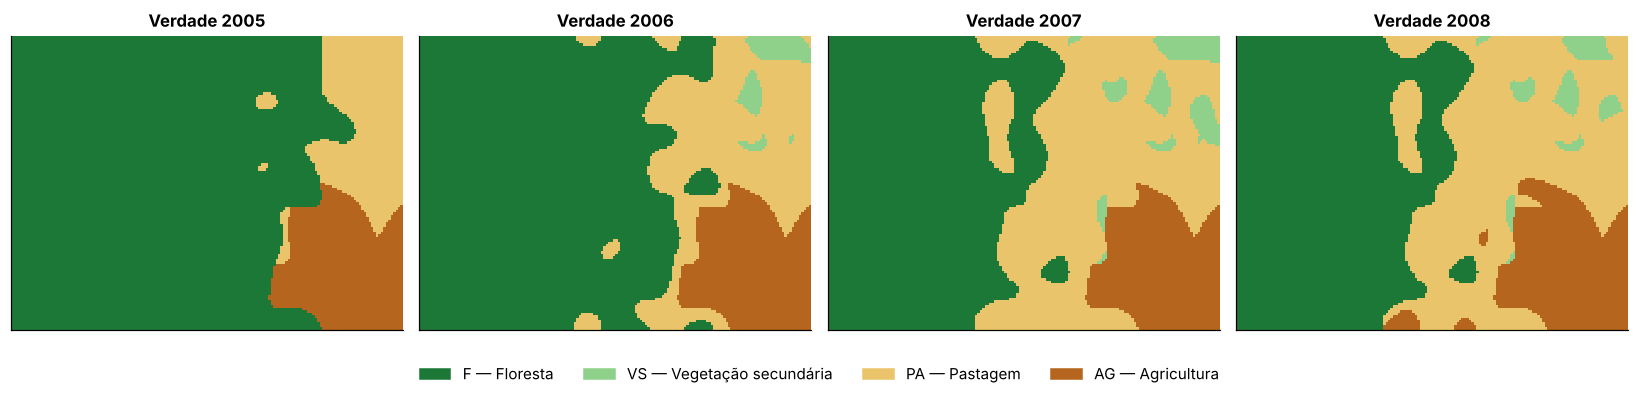

Trajetórias reais mais frequentes (% dos pixels):
F → F → F → F        48.22
F → F → PA → PA      14.76
AG → AG → AG → AG    12.39
F → PA → PA → PA     10.73
PA → PA → PA → PA     8.89
PA → VS → VS → VS     1.72
F → PA → PA → AG      0.68
F → PA → VS → VS      0.56


In [7]:
def campo_suave(h, w, sigma):
    """Campo aleatório espacialmente correlacionado (média 0, desvio 1), por filtragem Gaussiana via FFT."""
    ruido = rng.normal(size=(h, w))
    fy, fx = np.fft.fftfreq(h)[:, None], np.fft.fftfreq(w)[None, :]
    nucleo = np.exp(-2 * (np.pi * sigma) ** 2 * (fx ** 2 + fy ** 2))
    f = np.real(np.fft.ifft2(np.fft.fft2(ruido) * nucleo))
    return (f - f.mean()) / f.std()

H, W = 120, 160
ANOS = [2005, 2006, 2007, 2008]
T = len(ANOS)
iF, iVS, iPA, iAG = (CLASSES.index(c) for c in CLASSES)
yy, xx = np.mgrid[0:H, 0:W]

frente = xx + 14 * campo_suave(H, W, 7)                  # posição irregular da frente de desmatamento
zona_ag = yy + 12 * campo_suave(H, W, 8) > 78            # porção sul, mais favorável à agricultura

verdade = np.empty((T, H, W), dtype=int)
v = np.full((H, W), iF)
v[frente > 112] = iPA
v[(frente > 112) & zona_ag] = iAG
verdade[0] = v

v = verdade[0].copy()                                    # 2006
v[(frente > 96) & (frente <= 112)] = iPA                 # desmatamento
v[(campo_suave(H, W, 5) > 1.0) & (verdade[0] == iPA)] = iVS   # abandono da pastagem
verdade[1] = v

v = verdade[1].copy()                                    # 2007
v[(frente > 82) & (frente <= 96)] = iPA
v[(campo_suave(H, W, 5) > 1.0) & (verdade[1] == iPA) & ~zona_ag] = iVS
verdade[2] = v

v = verdade[2].copy()                                    # 2008
v[(campo_suave(H, W, 6) > 0.4) & (verdade[2] == iVS)] = iPA   # nova supressão da vegetação secundária
v[(campo_suave(H, W, 6) > 0.8) & (verdade[2] == iPA) & zona_ag] = iAG
verdade[3] = v

V = VALIDADE.to_numpy()
assert all(V[verdade[t], verdade[t + 1]].all() for t in range(T - 1)), 'a verdade contém transição inválida'

fig, axes = plt.subplots(1, T, figsize=(15, 3.6))
for t, ax in enumerate(axes):
    mostrar_classes(ax, verdade[t], f'Verdade {ANOS[t]}')
legenda_classes(fig, y=-0.04); plt.tight_layout(); plt.show()

traj_verdade = pd.Series([' → '.join(CLASSES[k] for k in verdade[:, i, j]) for i, j in zip(yy.ravel(), xx.ravel())])
print('Trajetórias reais mais frequentes (% dos pixels):')
print((100 * traj_verdade.value_counts(normalize=True)).head(8).round(2).to_string())

### 7.2 Observações e verossimilhanças

Cada classe gera observações em duas bandas a partir de uma Gaussiana bivariada. As classes foram escolhidas com **sobreposição** proposital: Floresta e Vegetação secundária são parecidas, assim como Pastagem e Agricultura. É essa confusão que faz o MaxVer produzir trajetórias inválidas.

Como o foco é o CMAP, as verossimilhanças $P(\vec{o}_t \mid \omega_t)$ são calculadas com os **parâmetros verdadeiros** da simulação (Eq. 2.6). Numa aplicação real, elas viriam de modelos estimados com amostras de treino, de qualquer distribuição.

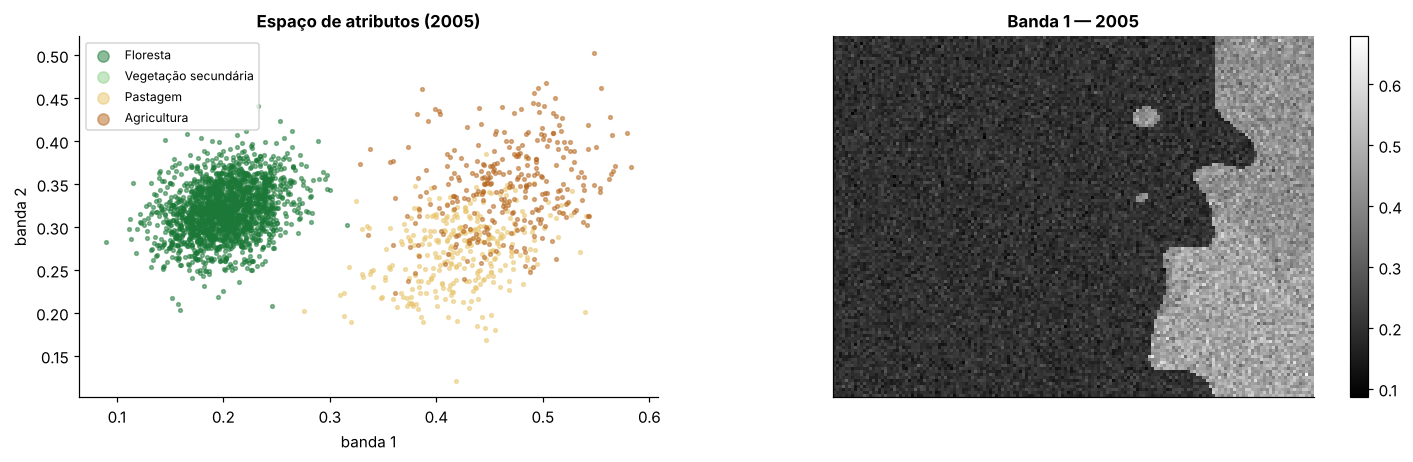

In [8]:
MEDIA = {'F': [0.20, 0.32], 'VS': [0.245, 0.355], 'PA': [0.42, 0.27], 'AG': [0.465, 0.35]}
DESVIO = {'F': [0.030, 0.030], 'VS': [0.040, 0.040], 'PA': [0.045, 0.040], 'AG': [0.050, 0.050]}
CORREL = 0.3
COV = {c: np.array([[DESVIO[c][0] ** 2, CORREL * DESVIO[c][0] * DESVIO[c][1]],
                    [CORREL * DESVIO[c][0] * DESVIO[c][1], DESVIO[c][1] ** 2]]) for c in CLASSES}

# Observações: (T, H, W, 2 bandas)
obs = np.empty((T, H, W, 2))
for t in range(T):
    for k, c in enumerate(CLASSES):
        m = verdade[t] == k
        obs[t][m] = rng.multivariate_normal(MEDIA[c], COV[c], m.sum())

# Log-verossimilhança Gaussiana bivariada (Eq. 2.6, em log): loglik[t, k, i, j] = log P(o_t | ω_t = k)
loglik = np.empty((T, K, H, W))
for k, c in enumerate(CLASSES):
    inv, (_, logdet) = np.linalg.inv(COV[c]), np.linalg.slogdet(COV[c])
    d = obs - np.array(MEDIA[c])
    maha = np.einsum('...i,ij,...j->...', d, inv, d)
    loglik[:, k] = -0.5 * (2 * np.log(2 * np.pi) + logdet + maha)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1, 1.25]})
amostra = rng.choice(H * W, 2500, replace=False)
for k, c in enumerate(CLASSES):
    sel = verdade[0].ravel()[amostra] == k
    axes[0].scatter(obs[0].reshape(-1, 2)[amostra][sel, 0], obs[0].reshape(-1, 2)[amostra][sel, 1],
                    s=6, alpha=0.5, color=CORES[c], label=NOMES[c])
axes[0].set_xlabel('banda 1'); axes[0].set_ylabel('banda 2'); axes[0].set_title('Espaço de atributos (2005)')
axes[0].legend(markerscale=3, fontsize=8)
im = axes[1].imshow(obs[0, :, :, 0], cmap='gray'); axes[1].set_title('Banda 1 — 2005')
axes[1].set_xticks([]); axes[1].set_yticks([]); plt.colorbar(im, ax=axes[1], fraction=0.035)
plt.tight_layout(); plt.show()

---
## 8. MaxVer + comparação pós-classificação

Cada data é classificada isoladamente (Eq. 2.5), e as classificações são empilhadas. Um pixel tem trajetória **inválida** quando alguma das suas transições consecutivas vale 0 na matriz de validade.

Pixels com trajetória inválida no MaxVer empilhado: 31.69%
Acerto do MaxVer por data: 2005: 82.6%, 2006: 82.8%, 2007: 82.6%, 2008: 82.9%


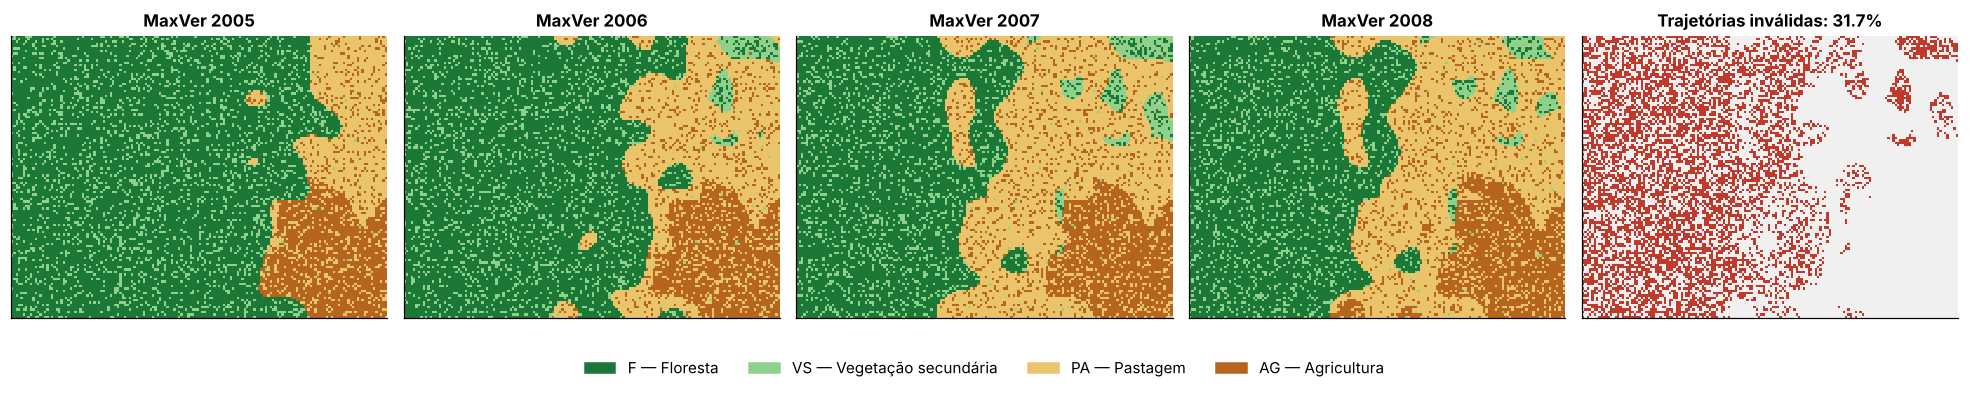

In [9]:
maxver = loglik.argmax(axis=1)                                     # (T, H, W): Eq. 2.5 em cada data

transicao_valida = np.stack([V[maxver[t], maxver[t + 1]] for t in range(T - 1)])   # (T-1, H, W)
invalida_maxver = (transicao_valida == 0).any(axis=0)                # alguma transição impossível
pct_invalida_maxver = 100 * invalida_maxver.mean()

acerto_maxver = [(maxver[t] == verdade[t]).mean() for t in range(T)]
print(f'Pixels com trajetória inválida no MaxVer empilhado: {pct_invalida_maxver:.2f}%')
print('Acerto do MaxVer por data:', ', '.join(f'{a}: {100 * x:.1f}%' for a, x in zip(ANOS, acerto_maxver)))

fig, axes = plt.subplots(1, T + 1, figsize=(18, 3.6))
for t in range(T):
    mostrar_classes(axes[t], maxver[t], f'MaxVer {ANOS[t]}')
axes[T].imshow(invalida_maxver, cmap=ListedColormap(['#f0f0f0', COR_INVALIDA]), interpolation='nearest')
axes[T].set_title(f'Trajetórias inválidas: {pct_invalida_maxver:.1f}%'); axes[T].set_xticks([]); axes[T].set_yticks([])
legenda_classes(fig, y=-0.04); plt.tight_layout(); plt.show()

O MaxVer produz o ruído "sal e pimenta" típico. Na floresta, aparecem pixels isolados de vegetação secundária, e em vários pixels a floresta "volta" depois de desmatada. Cada um desses casos é uma trajetória que não existe no mundo real.

---
## 9. CMAP na cena

### 9.1 Implementação

A implementação segue a mesma lógica do classificador do projeto (`cmap.cmap_classifier`):

1. **Enumerar as trajetórias** $\Omega = \Omega_1 \otimes \cdots \otimes \Omega_T$ e calcular $P(s)$ pela Eq. 2.12.
2. **Descartar** as trajetórias com $P(s) = 0$.
3. Para cada trajetória válida, somar $\log P(s) + \sum_t \log P(\vec{o}_t \mid \omega_t)$ em **todos os pixels de uma vez** (operação vetorizada).
4. Manter, pixel a pixel, a trajetória de maior pontuação. Em caso de empate, fica a de menor índice.

A função também guarda a **segunda melhor** pontuação, que será usada como medida de confiança. As legendas podem variar por data: as matrizes de transição podem ser retangulares ($K_{t-1} \times K_t$).

In [10]:
def priores_trajetorias(matrizes, p_inicial=None):
    """
    Todas as trajetórias (produto cartesiano das legendas) e P(s) pela Eq. 2.12.
    matrizes: lista de arrays (K_{t-1} x K_t), uma por par de datas consecutivas.
    p_inicial: vetor P(ω_1) ou None (uniforme).
    Returns: (trajetorias [S x T] com o índice da classe em cada data, P(s) [S])
    """
    Ks = [matrizes[0].shape[0]] + [m.shape[1] for m in matrizes]
    trajetorias = np.array(list(itertools.product(*[range(k) for k in Ks])))
    p = np.full(len(trajetorias), 1.0 / Ks[0]) if p_inicial is None else np.asarray(p_inicial)[trajetorias[:, 0]]
    for t, m in enumerate(matrizes):
        p = p * np.asarray(m)[trajetorias[:, t], trajetorias[:, t + 1]]
    return trajetorias, p


def cmap_classificar(loglik_por_data, trajetorias, prior):
    """
    CMAP (Eq. 2.11) em espaço logarítmico.
    loglik_por_data: lista de arrays (K_t, H, W) com log P(o_t | ω_t).
    Returns: (indice_trajetoria [H, W], melhor_pontuacao [H, W], segunda_pontuacao [H, W])
    """
    h, w = loglik_por_data[0].shape[1:]
    melhor = np.full((h, w), -np.inf)
    segunda = np.full((h, w), -np.inf)
    vencedora = np.full((h, w), -1)
    with np.errstate(divide='ignore'):
        log_prior = np.log(prior)
    for s in np.flatnonzero(prior > 0):                                # só trajetórias válidas
        pontuacao = log_prior[s] + sum(loglik_por_data[t][trajetorias[s, t]] for t in range(len(loglik_por_data)))
        maior = pontuacao > melhor                                     # empate: mantém a primeira
        segunda = np.where(maior, melhor, np.maximum(segunda, pontuacao))
        melhor = np.where(maior, pontuacao, melhor)
        vencedora = np.where(maior, s, vencedora)
    return vencedora, melhor, segunda

### 9.2 Execução — abordagens simplificada e discriminativa

In [11]:
mat_validade = [VALIDADE.to_numpy()] * (T - 1)
mat_discrim = [DISCRIMINATIVA.to_numpy()] * (T - 1)

trajetorias, prior_valid = priores_trajetorias(mat_validade)
N_s = int((prior_valid > 0).sum())
prior_simpl = np.where(prior_valid > 0, 1.0 / N_s, 0.0)               # P(s) = 1/N_s ou 0
_, prior_discr = priores_trajetorias(mat_discrim)

print(f'Trajetórias possíveis: {len(trajetorias)} (= {K}^{T}) | válidas: {N_s} | inválidas: {len(trajetorias) - N_s}')
print(f'Σ P(s) — simplificada: {prior_simpl.sum():.6f} | discriminativa: {prior_discr.sum():.6f}')

loglik_lista = [loglik[t] for t in range(T)]
t0 = time.time()
idx_simpl, melhor_simpl, segunda_simpl = cmap_classificar(loglik_lista, trajetorias, prior_simpl)
idx_discr, melhor_discr, segunda_discr = cmap_classificar(loglik_lista, trajetorias, prior_discr)
print(f'CMAP (duas abordagens) em {H * W} pixels: {time.time() - t0:.2f} s')

cmap_simpl = np.moveaxis(trajetorias[idx_simpl], -1, 0)              # (T, H, W): classe em cada data
cmap_discr = np.moveaxis(trajetorias[idx_discr], -1, 0)

Trajetórias possíveis: 256 (= 4^4) | válidas: 108 | inválidas: 148
Σ P(s) — simplificada: 1.000000 | discriminativa: 1.000000
CMAP (duas abordagens) em 19200 pixels: 0.02 s


### 9.3 Verificação independente

Confere-se o resultado do CMAP vetorizado contra a **definição literal** da Eq. 2.11 em 300 pixels sorteados: produto das verossimilhanças em escala linear (float64), multiplicado por $P(s)$, com arg max explícito sobre as 256 trajetórias.

In [12]:
pix = rng.choice(H * W, 300, replace=False)
ii, jj = np.unravel_index(pix, (H, W))
iguais = 0
for i, j in zip(ii, jj):
    veross = np.exp(loglik[:, :, i, j])                                   # (T, K) em escala linear
    produto = np.array([np.prod([veross[t, s[t]] for t in range(T)]) for s in trajetorias])
    iguais += np.argmax(prior_simpl * produto) == idx_simpl[i, j]
print(f'Definição literal × implementação vetorizada: {iguais} de {len(pix)} pixels idênticos')

Definição literal × implementação vetorizada: 300 de 300 pixels idênticos


---
## 10. Avaliação

### 10.1 Mapas

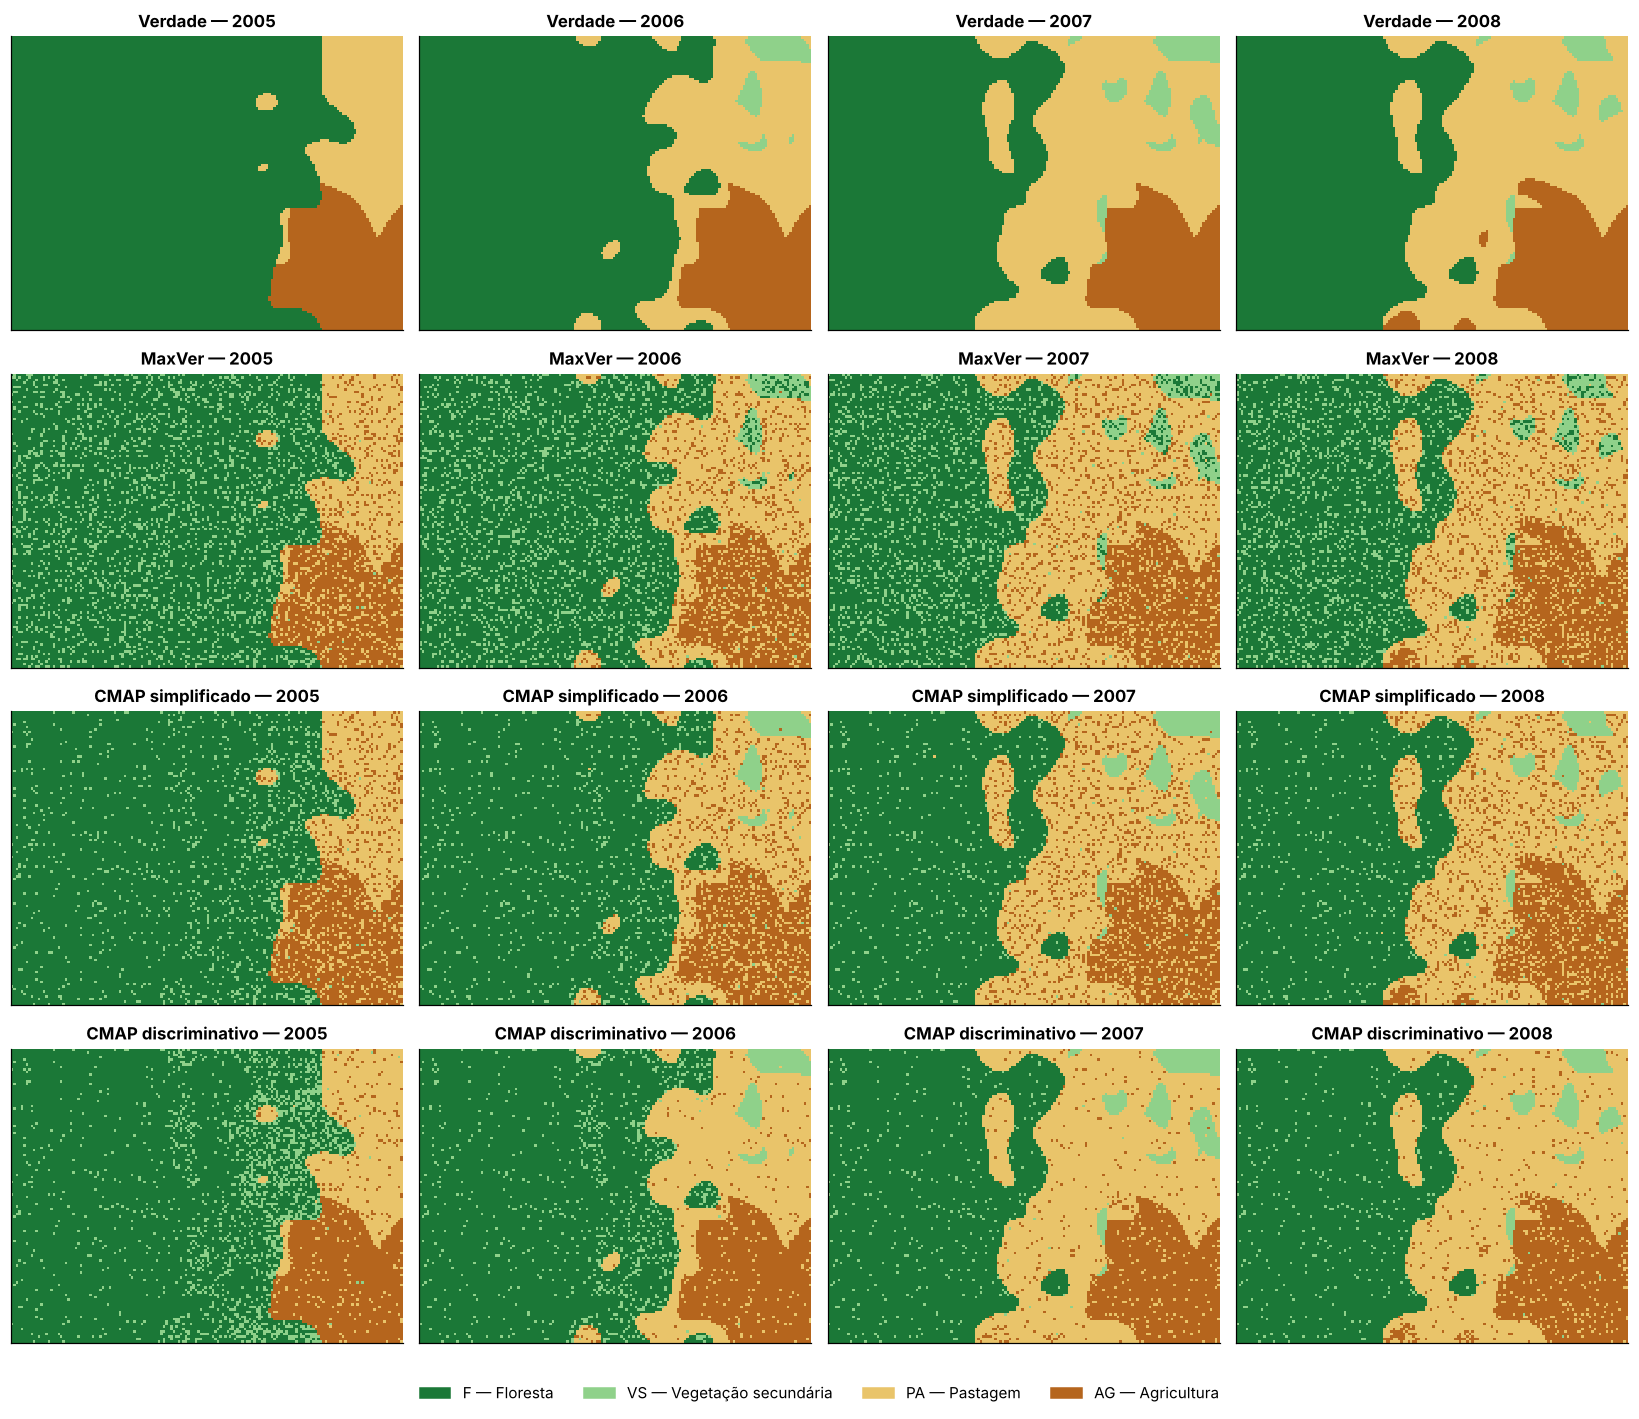

In [13]:
linhas_fig = [('Verdade', verdade), ('MaxVer', maxver), ('CMAP simplificado', cmap_simpl), ('CMAP discriminativo', cmap_discr)]
fig, axes = plt.subplots(len(linhas_fig), T, figsize=(15, 3.2 * len(linhas_fig)))
for r, (nome, serie) in enumerate(linhas_fig):
    for t in range(T):
        mostrar_classes(axes[r, t], serie[t], f'{nome} — {ANOS[t]}')
legenda_classes(fig, y=-0.01); plt.tight_layout(rect=(0, 0.02, 1, 1)); plt.show()

O efeito visual mais evidente é a **redução do ruído**. Os pixels isolados de VS dentro da floresta desaparecem, porque F → VS é impossível e a floresta não pode reaparecer depois. A vegetação secundária passa a se concentrar onde de fato houve desmatamento anterior. Isso acontece **sem nenhuma informação espacial (contextual)**: cada pixel é tratado de forma independente, e a melhora vem só do uso conjunto das datas. Reis et al. (2020b) descrevem o mesmo efeito na cena real.

### 10.2 Trajetórias inválidas e acurácia por data

Acerto por data e da trajetória completa (% dos pixels, contra a verdade); trajetórias inválidas (%):


,2005,2006,2007,2008,trajetória completa,trajetórias inválidas
MaxVer,82.62,82.82,82.58,82.89,46.86,31.69
CMAP simplificado,89.27,90.01,89.67,89.53,73.61,0.00
CMAP discriminativo,89.34,94.08,96.10,95.23,86.74,0.00


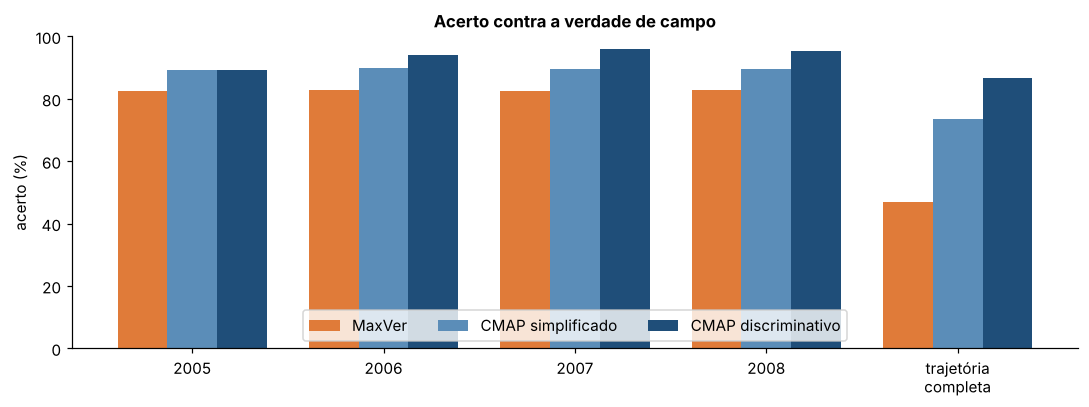

In [14]:
def pct_invalidas(serie):
    ok = np.stack([V[serie[t], serie[t + 1]] for t in range(T - 1)])
    return 100 * (ok == 0).any(axis=0).mean()

series = {'MaxVer': maxver, 'CMAP simplificado': cmap_simpl, 'CMAP discriminativo': cmap_discr}
resumo = pd.DataFrame({nome: {**{str(a): 100 * (s[t] == verdade[t]).mean() for t, a in enumerate(ANOS)},
                              'trajetória completa': 100 * (s == verdade).all(axis=0).mean(),
                              'trajetórias inválidas': pct_invalidas(s)}
                       for nome, s in series.items()}).T
print('Acerto por data e da trajetória completa (% dos pixels, contra a verdade); trajetórias inválidas (%):')
display(resumo.style.format('{:.2f}').highlight_max(subset=[str(a) for a in ANOS] + ['trajetória completa'],
                                                    props='font-weight:bold; background-color:#d6eaf8'))

fig, ax = plt.subplots(figsize=(10, 3.8))
largura = 0.26
for k, (nome, cor) in enumerate(zip(series, [COR_MAXVER, '#5b8db8', COR_CMAP])):
    valores = resumo.loc[nome, [str(a) for a in ANOS] + ['trajetória completa']]
    ax.bar(np.arange(T + 1) + (k - 1) * largura, valores, largura, label=nome, color=cor)
ax.set_xticks(range(T + 1), [str(a) for a in ANOS] + ['trajetória\ncompleta'])
ax.set_ylabel('acerto (%)'); ax.set_ylim(0, 100); ax.legend(ncol=3, loc='lower center')
ax.set_title('Acerto contra a verdade de campo'); plt.tight_layout(); plt.show()

Três observações:

1. **Trajetórias inválidas são 0% no CMAP, por construção**, nas duas abordagens. Trajetórias com $P(s) = 0$ nunca são avaliadas.
2. **O acerto por data também melhora**. É o "efeito secundário" descrito por Reis et al. (2020b): ao classificar só trajetórias válidas, o CMAP resolve confusões que, numa data isolada, não têm solução.
3. **O maior ganho está na trajetória completa**, que é o produto que interessa em estudos de dinâmica. No MaxVer empilhado, basta um erro em qualquer data para a trajetória inteira estar errada.

> **O prior também pode introduzir viés.** No mapa de 2005 do CMAP discriminativo, aparecem pixels de VS junto à frente de desmatamento. A matriz desta simulação dá probabilidade maior a VS → PA (0,15) que a F → PA (0,07). Para um pixel desmatado depois, a trajetória "VS → PA" fica mais provável a priori que "F → PA", e a classe do ano anterior ao desmatamento é puxada para VS. A matriz foi escrita à mão e **não** reflete a dinâmica real da cena, em que F → PA é a transição mais frequente. Na abordagem discriminativa, as probabilidades da matriz precisam vir de conhecimento real da área (dados históricos, mapeamentos, campo); valores arbitrários deslocam a classificação.

Os números aqui dependem da simulação, que tem confusão forte entre F e VS por construção. Eles ilustram o mecanismo e não substituem os resultados da dissertação.

### 10.3 Discordância entre MaxVer e CMAP

Na dissertação (Tabelas 5.7 a 5.9) e em Reis et al. (2020b, Tabela 3), a comparação é feita pela porcentagem de pixels em que os dois classificadores discordam, por data e na trajetória (pixel com pelo menos uma data diferente).

Discordância em relação ao MaxVer (% dos pixels):


,2005,2006,2007,2008,trajetória
CMAP simplificado,10.08,10.74,9.26,8.89,31.69
CMAP discriminativo,15.96,15.94,16.23,15.29,50.69


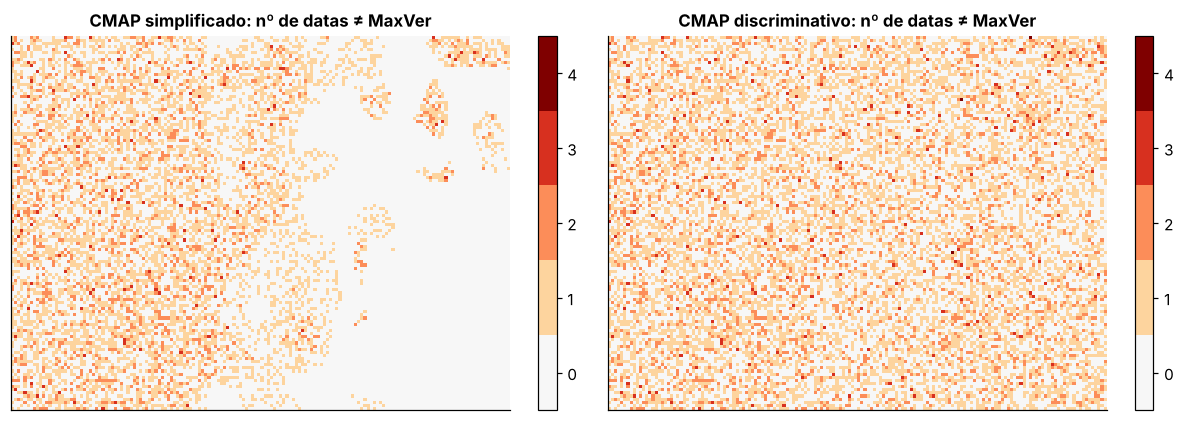

In [15]:
disc = pd.DataFrame({nome: {**{str(a): 100 * (s[t] != maxver[t]).mean() for t, a in enumerate(ANOS)},
                             'trajetória': 100 * (s != maxver).any(axis=0).mean()}
                     for nome, s in [('CMAP simplificado', cmap_simpl), ('CMAP discriminativo', cmap_discr)]}).T
print('Discordância em relação ao MaxVer (% dos pixels):')
display(disc.style.format('{:.2f}'))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (nome, s) in zip(axes, [('CMAP simplificado', cmap_simpl), ('CMAP discriminativo', cmap_discr)]):
    n_datas = (s != maxver).sum(axis=0)
    im = ax.imshow(n_datas, cmap=ListedColormap(['#f7f7f7', '#fdd49e', '#fc8d59', '#d7301f', '#7f0000'][:T + 1]),
                   vmin=-0.5, vmax=T + 0.5, interpolation='nearest')
    ax.set_title(f'{nome}: nº de datas ≠ MaxVer'); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, ticks=range(T + 1), fraction=0.035)
plt.tight_layout(); plt.show()

Repare que a discordância de trajetória do CMAP simplificado é **exatamente igual** à porcentagem de trajetórias inválidas do MaxVer (Seção 8). Isso vale sempre, e decorre da formulação: o MaxVer empilhado é a trajetória de maior verossimilhança composta entre **todas**. Se ela for válida, também é a maior entre as válidas, e o CMAP simplificado a escolhe sem alterar nada. O CMAP simplificado só muda os pixels cuja trajetória MaxVer é inválida, e muda todos eles.

Como em Reis et al. (2020b), a abordagem **discriminativa discorda mais do MaxVer** que a simplificada. A simplificada só intervém onde o MaxVer produziria uma transição impossível. A discriminativa, além disso, repondera as transições possíveis e favorece a permanência.

### 10.4 Matrizes de transição observadas

As transições contabilizadas nos mapas, somando os três pares de datas consecutivas, mostram onde estão os erros do MaxVer. As células com borda vermelha são transições **impossíveis**.

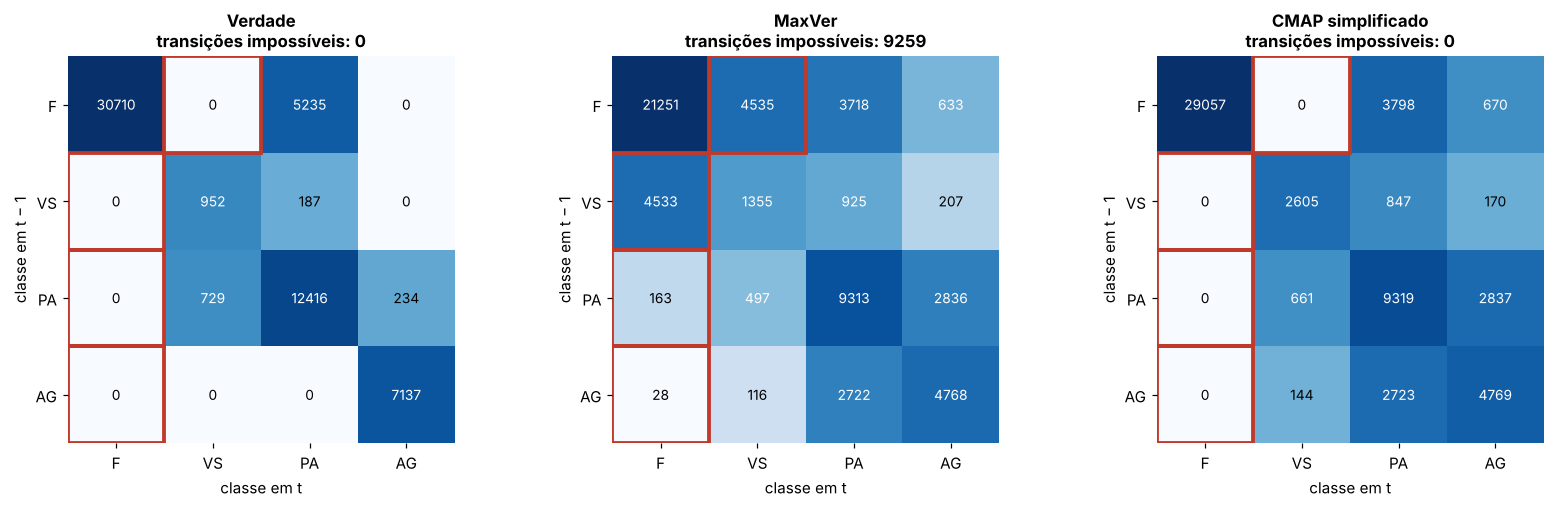

In [16]:
def contar_transicoes(serie):
    cont = np.zeros((K, K), dtype=int)
    for t in range(T - 1):
        np.add.at(cont, (serie[t].ravel(), serie[t + 1].ravel()), 1)
    return cont

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (nome, s) in zip(axes, [('Verdade', verdade), ('MaxVer', maxver), ('CMAP simplificado', cmap_simpl)]):
    cont = contar_transicoes(s)
    ax.imshow(np.log10(cont + 1), cmap='Blues')
    for (i, j), n in np.ndenumerate(cont):
        ax.text(j, i, f'{n}', ha='center', va='center', fontsize=9,
                color='white' if np.log10(n + 1) > 0.6 * np.log10(cont.max() + 1) else 'black')
        if V[i, j] == 0:
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=COR_INVALIDA, lw=2.5))
    ax.set_xticks(range(K), CLASSES); ax.set_yticks(range(K), CLASSES)
    ax.set_xlabel('classe em t'); ax.set_ylabel('classe em t − 1')
    n_inv = int(cont[V == 0].sum())
    ax.set_title(f'{nome}\ntransições impossíveis: {n_inv}'); ax.spines[:].set_visible(False)
plt.tight_layout(); plt.show()

### 10.5 Confiança da decisão

O CMAP fornece, para cada pixel, a pontuação da trajetória vencedora e da segunda colocada. A **margem** entre elas,

$$\Delta = \Big[\log P(\hat{s}) + \sum_t \log P(\vec{o}_t \mid \hat{\omega}_t)\Big] - \Big[\log P(s_2) + \sum_t \log P(\vec{o}_t \mid \omega^{(2)}_t)\Big]$$

é o logaritmo da razão entre as posteriores das duas melhores trajetórias. Por exemplo, $\Delta = 2$ significa que a vencedora é $e^2 \approx 7{,}4$ vezes mais provável que a segunda. Margens pequenas indicam pixels em que a escolha da trajetória é incerta. Essa medida não aparece nos trabalhos originais: é uma leitura derivada diretamente da Eq. 2.11.

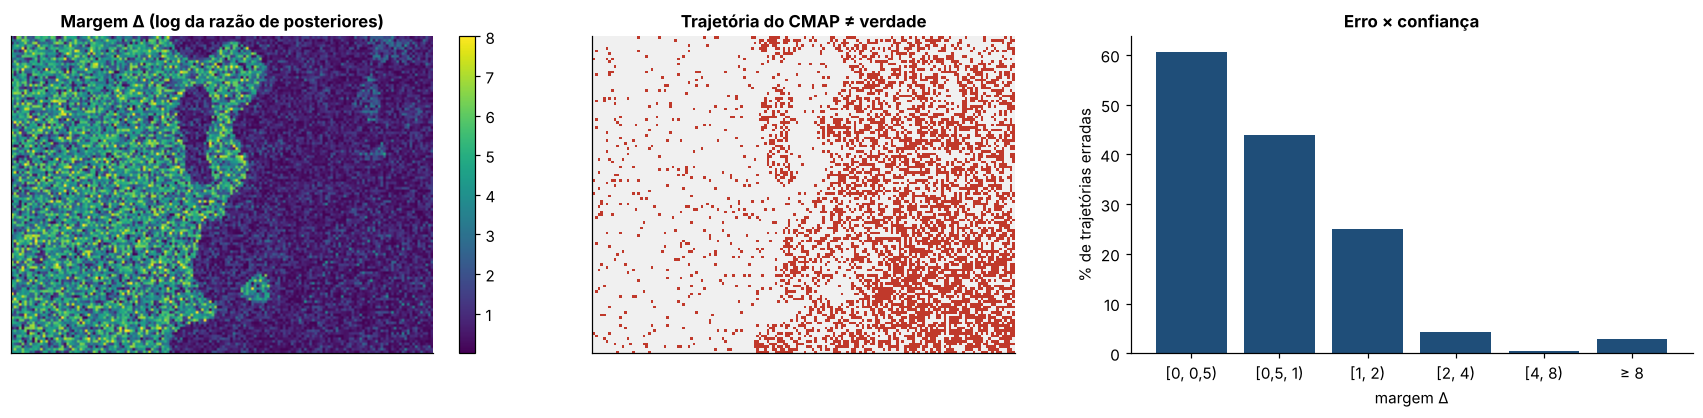

In [17]:
margem = melhor_simpl - segunda_simpl
traj_errada = (cmap_simpl != verdade).any(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.9), gridspec_kw={'width_ratios': [1, 1, 1.1]})
im = axes[0].imshow(np.clip(margem, 0, 8), cmap='viridis'); axes[0].set_title('Margem Δ (log da razão de posteriores)')
plt.colorbar(im, ax=axes[0], fraction=0.035); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[1].imshow(traj_errada, cmap=ListedColormap(['#f0f0f0', COR_INVALIDA]), interpolation='nearest')
axes[1].set_title('Trajetória do CMAP ≠ verdade'); axes[1].set_xticks([]); axes[1].set_yticks([])
faixas = [0, 0.5, 1, 2, 4, 8, np.inf]
grupo = pd.cut(margem.ravel(), faixas, right=False)
taxa = pd.Series(traj_errada.ravel()).groupby(grupo, observed=False).mean() * 100
axes[2].bar(range(len(taxa)), taxa.values, color=COR_CMAP)
axes[2].set_xticks(range(len(taxa)), ['[0, 0,5)', '[0,5, 1)', '[1, 2)', '[2, 4)', '[4, 8)', '≥ 8'])
axes[2].set_xlabel('margem Δ'); axes[2].set_ylabel('% de trajetórias erradas')
axes[2].set_title('Erro × confiança'); plt.tight_layout(); plt.show()

O erro se concentra nos pixels de margem pequena, o que torna a margem um bom indicador de **onde verificar** o resultado (por exemplo, para orientar coleta de amostras ou inspeção visual).

### 10.6 Trajetórias mais frequentes

In [18]:
def tabela_trajetorias(serie, n=10):
    rotulos = pd.Series([' → '.join(CLASSES[k] for k in serie[:, i, j]) for i, j in zip(yy.ravel(), xx.ravel())])
    return (100 * rotulos.value_counts(normalize=True)).head(n).round(2)

pd.concat({'Verdade': tabela_trajetorias(verdade), 'MaxVer': tabela_trajetorias(maxver),
           'CMAP simplificado': tabela_trajetorias(cmap_simpl)}, axis=1).fillna('—')

,Verdade,MaxVer,CMAP simplificado
F → F → F → F,48.22,22.89,45.94
F → F → PA → PA,14.76,7.43,9.56
AG → AG → AG → AG,12.39,4.79,4.79
F → PA → PA → PA,10.73,5.47,5.49
PA → PA → PA → PA,8.89,4.68,4.68
PA → VS → VS → VS,1.72,—,1.43
F → PA → PA → AG,0.68,—,—
F → PA → VS → VS,0.56,—,—
PA → PA → VS → PA,0.56,—,—
PA → PA → VS → VS,0.55,—,—


---
## 11. Datas com nuvem

Uma consequência direta da formulação é o tratamento de observações ausentes. Se uma data está coberta por nuvem num pixel, a observação naquela data **não informa nada** sobre a classe. Isso equivale a fazer $P(\vec{o}_t \mid \omega_t)$ constante para todas as classes, ou seja, $\log P(\vec{o}_t \mid \omega_t) = 0$ nesse pixel. A Eq. 2.11 continua valendo, e a classe daquela data passa a ser decidida pelas **outras datas** e por $P(s)$.

Esse é o modo `mask_mode='ignore'` do `cmap.cmap_classifier` do projeto. O `CMAP_classifier` original em R faz diferente (`mask_mode='output'`): usa a verossimilhança da data nublada normalmente e só mascara o pixel na saída.

Na simulação, uma nuvem cobre parte da frente de desmatamento em **2007**:

Pixels sob nuvem: 2256 (11.8% da cena)
Acerto em 2007 sob a nuvem — CMAP discriminativo: 56.6% | repetir MaxVer de 2006: 50.0%
  classe igual em 2006 e 2008 :  1295 pixels | acerto do CMAP em 2007: 94.6%
  mudou entre 2006 e 2008     :   961 pixels | acerto do CMAP em 2007: 5.3%


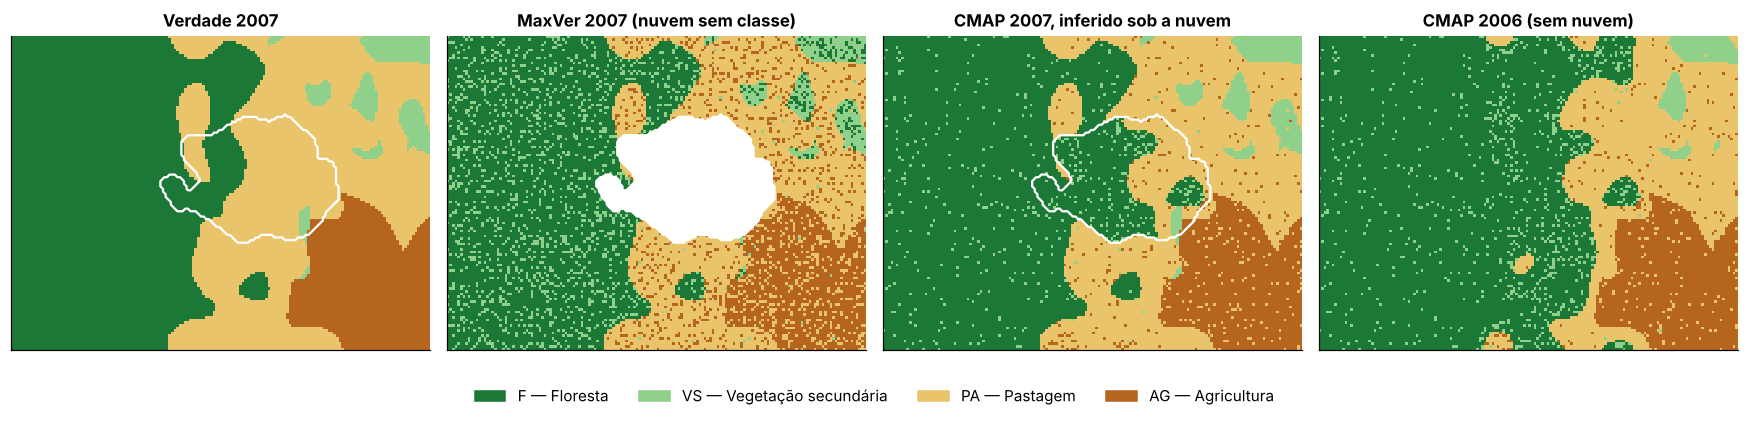

In [19]:
nuvem = (((yy - 55) / 22) ** 2 + ((xx - 95) / 30) ** 2 + 0.25 * campo_suave(H, W, 4)) < 1
t_nuvem = ANOS.index(2007)

loglik_nuvem = [ll.copy() for ll in loglik_lista]
loglik_nuvem[t_nuvem][:, nuvem] = 0.0                       # a data nublada não informa nada nesses pixels

idx_n, _, _ = cmap_classificar(loglik_nuvem, trajetorias, prior_discr)
cmap_nuvem = np.moveaxis(trajetorias[idx_n], -1, 0)

# Referência ingênua: repetir em 2007 a classe MaxVer de 2006
acerto_cmap = 100 * (cmap_nuvem[t_nuvem][nuvem] == verdade[t_nuvem][nuvem]).mean()
acerto_repetir = 100 * (maxver[t_nuvem - 1][nuvem] == verdade[t_nuvem][nuvem]).mean()
print(f'Pixels sob nuvem: {nuvem.sum()} ({100 * nuvem.mean():.1f}% da cena)')
print(f'Acerto em 2007 sob a nuvem — CMAP discriminativo: {acerto_cmap:.1f}% | repetir MaxVer de 2006: {acerto_repetir:.1f}%')

# Decomposição: pixels em que a classe real não muda entre 2006 e 2008 x pixels que mudaram nesse intervalo
estavel = (verdade[t_nuvem - 1] == verdade[t_nuvem + 1]) & nuvem
mudou = ~(verdade[t_nuvem - 1] == verdade[t_nuvem + 1]) & nuvem
for nome, m in [('classe igual em 2006 e 2008', estavel), ('mudou entre 2006 e 2008', mudou)]:
    print(f'  {nome:<28}: {m.sum():5d} pixels | acerto do CMAP em 2007: {100 * (cmap_nuvem[t_nuvem][m] == verdade[t_nuvem][m]).mean():.1f}%')

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
mostrar_classes(axes[0], verdade[t_nuvem], 'Verdade 2007')
mostrar_classes(axes[1], maxver[t_nuvem], 'MaxVer 2007 (nuvem sem classe)', mascara=nuvem)
mostrar_classes(axes[2], cmap_nuvem[t_nuvem], 'CMAP 2007, inferido sob a nuvem')
for ax in axes[:3]:
    ax.contour(nuvem, levels=[0.5], colors='white', linewidths=1.5)
mostrar_classes(axes[3], cmap_nuvem[t_nuvem - 1], 'CMAP 2006 (sem nuvem)')
legenda_classes(fig, y=-0.04); plt.tight_layout(); plt.show()

Sob a nuvem, o CMAP atribui a classe de 2007 combinando a evidência de 2006 e 2008 com as probabilidades de transição. Por exemplo, um pixel que era F em 2006 e PA em 2008 pode ter sido F ou PA em 2007, mas não VS.

A decomposição mostra onde está o limite. Nos pixels sem mudança entre 2006 e 2008, a inferência é quase sempre correta. Nos pixels que mudaram nesse intervalo (por exemplo, F em 2006 e PA em 2008), **o ano exato da mudança não é observável**: tanto F → F → PA quanto F → PA → PA são compatíveis com os dados. A escolha fica a cargo da matriz de transição, e aqui F → F → PA ($0{,}90 \times 0{,}07$) vence F → PA → PA ($0{,}07 \times 0{,}80$). Nenhum classificador pode resolver essa ambiguidade sem uma observação naquela data.

Dois cuidados:
- com a **abordagem simplificada**, todas as classes válidas no meio da trajetória ficam **empatadas** sob a nuvem, e o empate é resolvido pela ordem das trajetórias. A inferência só é informativa com probabilidades de transição (abordagem discriminativa);
- a classe inferida sob a nuvem é uma **estimativa a partir do prior**, não uma observação. Em análises de mudança, vale manter a máscara de nuvem junto do resultado.

---
## 12. Sensores e legendas diferentes em cada data

Como $\Omega = \Omega_1 \otimes \cdots \otimes \Omega_T$, nada exige que todas as datas tenham a mesma legenda. Reis et al. (2020b, estudo de caso 2) e o cenário C2 da dissertação classificam juntas imagens SAR e ópticas, cada uma com o nível de legenda que o sensor consegue discriminar. Nesse caso, as matrizes de transição são **retangulares**, $K_{t-1} \times K_t$.

Simula-se aqui que, em **2006**, o sensor só separa **VEG** (vegetação: F + VS) de **NVEG** (não vegetação: PA + AG). A verossimilhança de cada classe agregada é a mistura, com pesos iguais, das densidades das classes que ela contém:

$$P(\vec{o} \mid \text{VEG}) = \tfrac{1}{2}\big[P(\vec{o} \mid \text{F}) + P(\vec{o} \mid \text{VS})\big]$$

,F,VS,PA,AG
VEG,1,1,1,1
NVEG,1,1,1,1


,F,VS,PA,AG
VEG,1,1,1,1
NVEG,0,1,1,1


Trajetórias: 128 (= 4 × 2 × 4 × 4) | válidas: 84


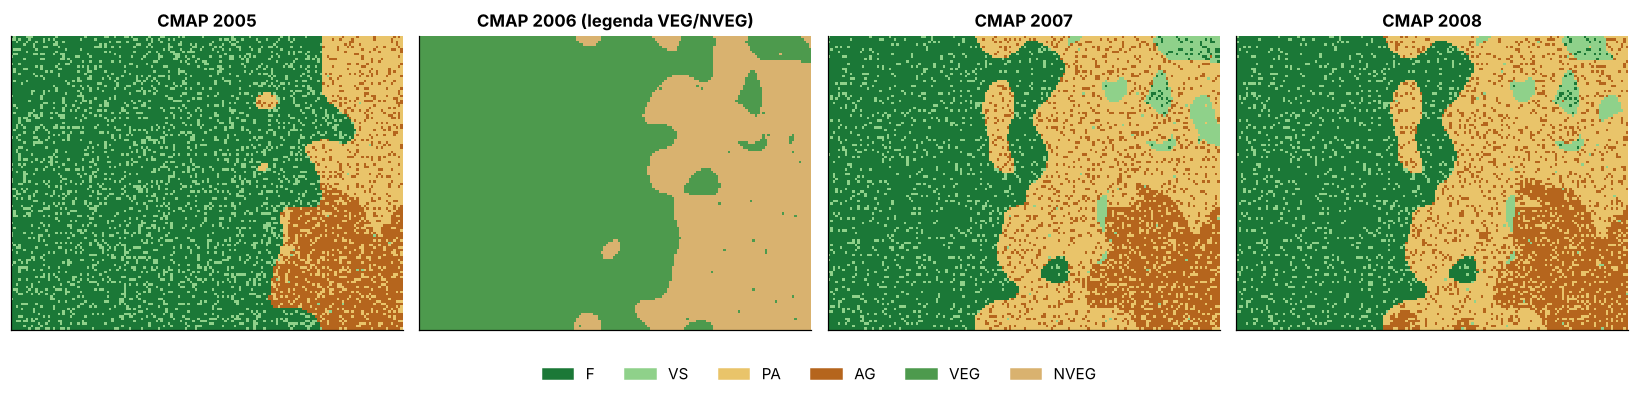

Acerto 2005 — CMAP com 2006 grosseira: 82.6% | CMAP simplificado original: 89.3%
Acerto 2007 — CMAP com 2006 grosseira: 86.3% | CMAP simplificado original: 89.7%
Acerto 2008 — CMAP com 2006 grosseira: 86.3% | CMAP simplificado original: 89.5%


In [20]:
LEG_2006 = ['VEG', 'NVEG']
CORES_GROSSAS = ['#4d9a4d', '#d9b26f']
membros = {'VEG': [iF, iVS], 'NVEG': [iPA, iAG]}

t2006 = ANOS.index(2006)
loglik_2006 = np.stack([np.logaddexp(loglik[t2006, a], loglik[t2006, b]) - np.log(2) for a, b in membros.values()])

# Matrizes retangulares: 2005 (4 classes) -> 2006 (2 classes) -> 2007 (4 classes)
v_05_06 = pd.DataFrame([[1, 1],     # F  -> VEG (permanece F), NVEG (desmatamento)
                        [1, 1],     # VS -> VEG, NVEG
                        [1, 1],     # PA -> VEG (abandono: VS), NVEG
                        [1, 1]],    # AG -> VEG (abandono: VS), NVEG
                       index=CLASSES, columns=LEG_2006)
v_06_07 = pd.DataFrame([[1, 1, 1, 1],    # VEG  -> F (se era F), VS, PA, AG
                        [0, 1, 1, 1]],   # NVEG -> nunca F
                       index=LEG_2006, columns=CLASSES)
display(v_05_06.T.style.set_caption('2005 → 2006 (transposta)'), v_06_07.style.set_caption('2006 → 2007'))

mats_multi = [v_05_06.to_numpy(), v_06_07.to_numpy(), VALIDADE.to_numpy()]
traj_multi, prior_multi = priores_trajetorias(mats_multi)
prior_multi = np.where(prior_multi > 0, 1.0 / (prior_multi > 0).sum(), 0.0)
loglik_multi = [loglik[0], loglik_2006, loglik[2], loglik[3]]
print(f'Trajetórias: {len(traj_multi)} (= 4 × 2 × 4 × 4) | válidas: {(prior_multi > 0).sum()}')

idx_m, _, _ = cmap_classificar(loglik_multi, traj_multi, prior_multi)
cmap_multi = np.moveaxis(traj_multi[idx_m], -1, 0)

fig, axes = plt.subplots(1, T, figsize=(15, 3.6))
for t, ax in enumerate(axes):
    if t == t2006:
        ax.imshow(cmap_multi[t], cmap=ListedColormap(CORES_GROSSAS), vmin=-0.5, vmax=1.5, interpolation='nearest')
        ax.set_title('CMAP 2006 (legenda VEG/NVEG)'); ax.set_xticks([]); ax.set_yticks([])
    else:
        mostrar_classes(ax, cmap_multi[t], f'CMAP {ANOS[t]}')
fig.legend(handles=[Patch(color=CORES[c], label=c) for c in CLASSES] +
                   [Patch(color=cc, label=n) for cc, n in zip(CORES_GROSSAS, LEG_2006)],
           loc='lower center', ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.show()

for t in (0, 2, 3):
    print(f'Acerto {ANOS[t]} — CMAP com 2006 grosseira: {100 * (cmap_multi[t] == verdade[t]).mean():.1f}% '
          f'| CMAP simplificado original: {100 * (cmap_simpl[t] == verdade[t]).mean():.1f}%')

Com a legenda grosseira em 2006, o CMAP continua produzindo trajetórias coerentes com as matrizes, e as datas de legenda detalhada são classificadas normalmente. Há, porém, uma **perda de restrição**. Como "VEG" pode ser F ou VS, a regra "F nunca vira VS" deixa de ser verificável entre 2005 e 2007 através de 2006. A matriz VEG → VS precisa permitir a transição, porque um pixel VEG pode ter sido VS. Legendas mais grosseiras tornam a série menos restritiva, e isso aparece no acerto das datas vizinhas.

Esse é o compromisso dos cenários multissensores: o ganho de ter uma observação (por exemplo, SAR numa data com nuvens nas imagens ópticas) contra a perda de detalhe da legenda daquela data.

---
## 13. Custo computacional e uma observação sobre o algoritmo de Viterbi

O número de trajetórias cresce exponencialmente com o número de datas:

$$|\Omega| = \prod_{t=1}^{T} K_t$$

Com 10 classes em 6 datas, são $10^6$ trajetórias. O custo da enumeração é proporcional a $(\text{trajetórias válidas}) \times T \times (\text{pixels})$, e a abordagem simplificada ajuda porque só as válidas são avaliadas. Mesmo assim, séries longas ou legendas detalhadas tornam a enumeração cara.

> **Observação (não está nos trabalhos originais; é uma constatação feita aqui).** Quando $P(s)$ se fatora como uma cadeia de Markov (Eq. 2.12), como nas duas abordagens deste notebook, a Eq. 2.11 é **exatamente** o problema de decodificação de um modelo oculto de Markov (HMM): estados ocultos = classes, emissões = verossimilhanças, transições = matrizes. O arg max pode então ser calculado pelo **algoritmo de Viterbi** (programação dinâmica), com custo $\sum_t K_{t-1} K_t$ por pixel em vez de $\prod_t K_t$, e com o mesmo resultado.
>
> A equivalência **não vale** quando $P(s)$ é dada por uma tabela arbitrária de pesos por trajetória que não se fatora em matrizes. Nesse caso, a enumeração continua necessária.

A célula abaixo implementa o Viterbi e confere que ele dá a mesma trajetória que a enumeração na abordagem discriminativa.

Mesma trajetória em 100.00% dos pixels | mesma pontuação: True
Tempo — enumeração: 0.019 s | Viterbi: 0.007 s


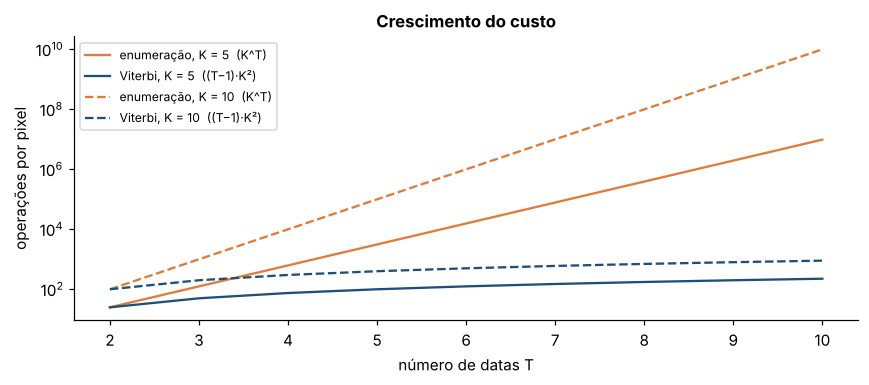

In [21]:
def viterbi(loglik_por_data, matrizes, p_inicial=None):
    """Decodificação de Viterbi (arg max de P(s)·∏P(o|ω) com P(s) markoviano), vetorizada por pixel."""
    K1 = loglik_por_data[0].shape[0]
    log_p0 = np.log(np.full(K1, 1.0 / K1) if p_inicial is None else np.asarray(p_inicial))
    delta = log_p0[:, None, None] + loglik_por_data[0]                         # (K_1, H, W)
    retorno = []
    with np.errstate(divide='ignore'):
        for t, m in enumerate(matrizes):
            cand = delta[:, None] + np.log(np.asarray(m))[:, :, None, None]     # (K_{t-1}, K_t, H, W)
            retorno.append(cand.argmax(axis=0))
            delta = cand.max(axis=0) + loglik_por_data[t + 1]
    caminho = [delta.argmax(axis=0)]
    for r in reversed(retorno):
        caminho.insert(0, np.take_along_axis(r, caminho[0][None], axis=0)[0])
    return np.stack(caminho), delta.max(axis=0)

t0 = time.time(); vit, score_vit = viterbi(loglik_lista, mat_discrim); t_vit = time.time() - t0
t0 = time.time(); _ = cmap_classificar(loglik_lista, trajetorias, prior_discr); t_enum = time.time() - t0
print(f'Mesma trajetória em {100 * (vit == cmap_discr).all(axis=0).mean():.2f}% dos pixels | '
      f'mesma pontuação: {np.allclose(score_vit, melhor_discr)}')
print(f'Tempo — enumeração: {t_enum:.3f} s | Viterbi: {t_vit:.3f} s')

datas = np.arange(2, 11)
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, estilo in [(5, '-'), (10, '--')]:
    ax.semilogy(datas, float(k) ** datas, estilo, color=COR_MAXVER, label=f'enumeração, K = {k}  (K^T)')
    ax.semilogy(datas, (datas - 1) * k ** 2, estilo, color=COR_CMAP, label=f'Viterbi, K = {k}  ((T−1)·K²)')
ax.set_xlabel('número de datas T'); ax.set_ylabel('operações por pixel')
ax.set_title('Crescimento do custo'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

---
## 14. Correspondência com o código do projeto e referências

### 14.1 Correspondência

| Este notebook | Pacote `sar_classification` | Código original |
|---|---|---|
| `priores_trajetorias` | `transitions.trajectory_priors`, `transitions.create_transition_matrix_table` | `create_transition_matrix_table` (`CMAP_FUNCTIONS.ipynb`) |
| `cmap_classificar` | `cmap.cmap_classifier` (mesma regra: log, só trajetórias válidas, empate → primeira) | `CMAP_classifier` (`CMAP_C4_C5.R`) |
| máscara com $\log P = 0$ (Seção 11) | `cmap.cmap_classifier(..., mask_mode='ignore')` | — (o R usa o equivalente a `'output'`) |
| MaxVer a partir das verossimilhanças | `cmap.maxver_from_likelihoods` | MaxVer dos scripts `MaxVer_SAR_*` |
| trajetórias inválidas (Seção 10.2) | `trajectory_assessment.impossible_trajectories` | `calcularTransicoesImpossiveis` (`trajectory_assessment.R`) |
| discordância MaxVer × CMAP (Seção 10.3) | `trajectory_assessment.compare_classifications` | `compareRasterClassification` |
| legendas diferentes por data (Seção 12) | `bands_config` / `classes_bandas` + matrizes retangulares | cenário C2 da dissertação |

As funções deste notebook reproduzem a **lógica** do pacote em arrays NumPy, sem leitura e gravação de GeoTIFF. Em dados reais, use o pacote, que trata nodata, grava os resultados com georreferenciamento e foi validado contra o código R original.

### 14.2 Resumo

- O CMAP classifica a série **diretamente em trajetórias**, maximizando $P(s)\prod_t P(\vec{o}_t \mid \omega_t)$ (Eq. 2.11).
- $P(s)$ incorpora o conhecimento da dinâmica: pela cadeia de Markov (Eq. 2.12), com matrizes de probabilidade (**discriminativa**) ou de validade (**simplificada**).
- Com $P(s)$ uniforme, o CMAP coincide com o MaxVer empilhado. A diferença vem toda do prior.
- Por construção, **não produz trajetórias inválidas**. Como efeito secundário, melhora a classificação de cada data e reduz o ruído, sem usar contexto espacial.
- Aceita qualquer fonte de verossimilhança, legendas diferentes por data e datas com observações ausentes.

### 14.3 Referências

- QUEIROZ, V. D. B. **Classificação de trajetórias de cobertura da terra utilizando uma abordagem de Máximo a Posteriori Composto em imagens de multissensores**. Dissertação (Mestrado em Sensoriamento Remoto) — INPE, São José dos Campos, 2024.
- REIS, M. S.; DUTRA, L. V.; ESCADA, M. I. S. Simultaneous multi-source and multi-temporal land cover classification using a Compound Maximum Likelihood classifier. In: **Proceedings XVIII GEOINFO**, Salvador, 2017. p. 74–85.
- REIS, M. S.; DUTRA, L. V.; ESCADA, M. I. S.; SANT'ANNA, S. J. S. Avoiding invalid transitions in land cover trajectory classification with a Compound Maximum a Posteriori approach. **IEEE Access**, v. 8, p. 98787–98799, 2020b. doi:10.1109/ACCESS.2020.2997019.
- REIS, M. S.; ESCADA, M. I. S.; SANT'ANNA, S. J. S.; DUTRA, L. V. Métodos de classificação e análise de trajetórias de uso e cobertura da terra na Amazônia: implicações para estudos de regeneração florestal. **Revista Brasileira de Cartografia**, v. 72, p. 1087–1113, 2020a.
- RABINER, L. R. A tutorial on hidden Markov models and selected applications in speech recognition. **Proceedings of the IEEE**, v. 77, n. 2, p. 257–286, 1989 — referência clássica para o algoritmo de Viterbi (Seção 13); citada de memória, não consta da dissertação.